# Tugas UTS Machine Learning
## Linear Regression dan Logistic Regression

**Nama:** Kiki Damayanti  
**NIM:** 211011400758  
**Kelas:** Reguler B  
**Random state:** `58` (dua digit terakhir NIM)

### Tujuan
Notebook ini digunakan untuk mempelajari dua jenis model machine learning:
- **Linear Regression** untuk memperkirakan nilai penjualan berdasarkan biaya iklan.
- **Logistic Regression** untuk mengklasifikasikan email sebagai spam atau bukan spam.

Implementasi utama, pembagian data, dan metrik evaluasi dibuat menggunakan **NumPy**. `scikit-learn` hanya digunakan pada bagian bonus sebagai pembanding.

### Cara menjalankan
1. Pastikan `Ads_Data.csv` dan `Email_Data.csv` berada di folder yang sama dengan notebook.
2. Jalankan seluruh sel secara berurutan dengan memilih **Run All**.
3. Periksa tabel, grafik, dan kesimpulan yang muncul setelah kode dijalankan.

> Catatan: hasil evaluasi bergantung pada dataset dan pembagian data. Gunakan angka yang tampil dari hasil eksekusi notebook ini saat menulis kesimpulan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 58
np.set_printoptions(precision=4, suppress=True)

## Persiapan: fungsi pembagian data dan metrik

Fungsi pada bagian ini dibuat tanpa `scikit-learn`. `train_test_split` mengacak indeks dengan `random_state` tetap agar hasil pembagian dapat diulang. Metrik regresi dan klasifikasi digunakan untuk menilai performa model pada data yang tidak dipakai saat pelatihan.

In [2]:
def train_test_split(X, y, test_size=0.2, random_state=0):
    """Split acak tanpa scikit-learn. Urutan X dan y tetap berpasangan."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

def mse(y_true, y_pred):
    return np.mean((np.asarray(y_true) - np.asarray(y_pred))**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true-y_pred)**2)
    ss_tot = np.sum((y_true-np.mean(y_true))**2)
    return 1 - ss_res/ss_tot if ss_tot != 0 else np.nan

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    # Urutan: [[TN, FP], [FN, TP]]
    return np.array([
        [np.sum((y_true==0)&(y_pred==0)), np.sum((y_true==0)&(y_pred==1))],
        [np.sum((y_true==1)&(y_pred==0)), np.sum((y_true==1)&(y_pred==1))]
    ])

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tp+tn)/(tp+tn+fp+fn) if tp+tn+fp+fn else 0
    precision = tp/(tp+fp) if tp+fp else 0
    recall = tp/(tp+fn) if tp+fn else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    return {"Accuracy":accuracy, "Precision":precision, "Recall":recall, "F1-score":f1,
            "TN":tn, "FP":fp, "FN":fn, "TP":tp}

def sigmoid(z):
    # Clip mencegah overflow numerik pada exp
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

## Bagian A – Linear Regression

### A1 – Load & visualisasi data

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


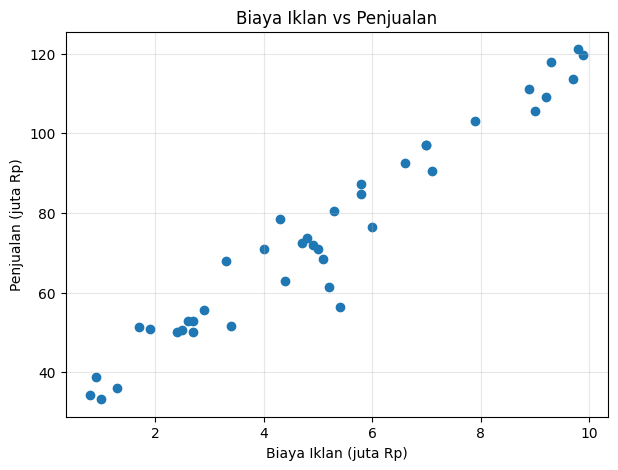

In [3]:
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris:", len(ads))

X = ads[["BiayaIklan"]].to_numpy(dtype=float)  # bentuk (n, 1)
y = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7,5))
plt.scatter(X[:,0], y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, alpha=0.3)
plt.show()

**Analisis A1:** Data terdiri dari 40 pengamatan. Scatter plot memperlihatkan kecenderungan hubungan positif: ketika biaya iklan lebih tinggi, penjualan umumnya juga lebih tinggi, meskipun terdapat variasi antarbulan.

### A2 – Split data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### A3 – Normal Equation

In [5]:
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

lin_model = LinearRegression().fit(X_train, y_train)
print("Intercept:", lin_model.intercept_)
print("Koefisien:", lin_model.coef_[0])
print(f"Persamaan: Penjualan = {lin_model.intercept_:.4f} + ({lin_model.coef_[0]:.4f} × BiayaIklan)")

Intercept: 26.96410209662742
Koefisien: 9.315614012241141
Persamaan: Penjualan = 26.9641 + (9.3156 × BiayaIklan)


**Jawaban A3 (interpretasi):** Intercept adalah perkiraan penjualan ketika biaya iklan 0 juta rupiah, sehingga interpretasinya perlu hati-hati jika nilai 0 berada di luar atau dekat luar rentang pengamatan. Koefisien menunjukkan perubahan rata-rata penjualan (juta Rp) untuk setiap kenaikan biaya iklan 1 juta Rp. Gunakan angka koefisien yang tercetak di atas untuk mengisi interpretasi.

### A4 – Evaluasi model

In [6]:
y_train_pred = lin_model.predict(X_train)
y_test_pred = lin_model.predict(X_test)

reg_results = pd.DataFrame([
    {"Data":"Training", "MAE":mae(y_train,y_train_pred), "MSE":mse(y_train,y_train_pred),
     "RMSE":rmse(y_train,y_train_pred), "R²":r2_score(y_train,y_train_pred)},
    {"Data":"Testing", "MAE":mae(y_test,y_test_pred), "MSE":mse(y_test,y_test_pred),
     "RMSE":rmse(y_test,y_test_pred), "R²":r2_score(y_test,y_test_pred)}
])
display(reg_results.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,4.3504,36.2741,6.0228,0.9472
1,Testing,5.1478,36.7506,6.0622,0.8611


**Analisis A4:** Berdasarkan tabel, model memperoleh MAE **4,3504** dan RMSE **6,0228** pada data training, sedangkan pada data testing MAE **5,1478** dan RMSE **6,0622**. Nilai R² testing adalah **0,8611**, sehingga model menjelaskan sekitar 86,11% variasi penjualan pada sampel testing. Perbedaan performa training dan testing relatif kecil pada hasil ini, tetapi evaluasi pada dataset lain tetap diperlukan untuk memastikan kemampuan generalisasi.

### A5 – Gradient Descent & learning rate

Learning rate=0.001: intercept=23.6213, koefisien=9.81177, loss akhir=38.5747
Learning rate=0.02: intercept=26.9641, koefisien=9.31561, loss akhir=36.2741
Learning rate=0.1: divergen (loss/gradien tidak lagi finite setelah 188 iterasi stabil).

Normal Equation: intercept = 26.96410209662742 , koefisien = 9.315614012241141
Catatan: kurva learning rate=0.1 hanya menampilkan iterasi sebelum divergensi.


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


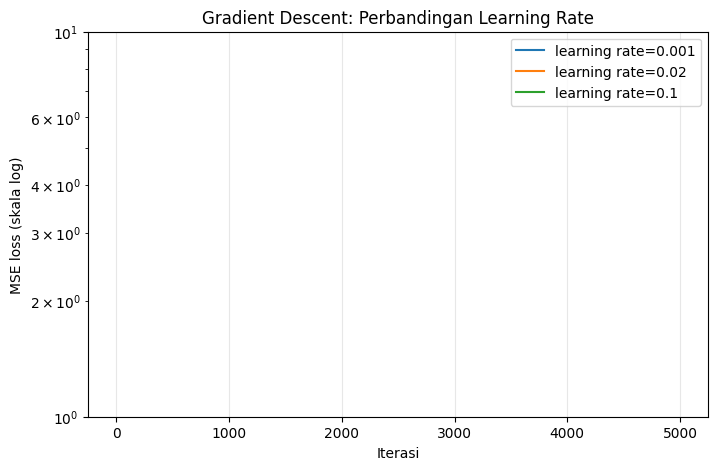

In [7]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        self.diverged_ = False

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_b.shape[1])
        self.loss_history = []
        self.diverged_ = False

        # Periksa nilai numerik agar learning rate yang terlalu besar
        # dilaporkan sebagai divergen, bukan hanya menghasilkan NaN.
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            for _ in range(self.n_iterations):
                errors = X_b @ theta - y
                loss = np.mean(errors ** 2)
                gradients = (2 / len(X)) * (X_b.T @ errors)
                if not np.isfinite(loss) or not np.all(np.isfinite(gradients)):
                    self.diverged_ = True
                    break
                self.loss_history.append(float(loss))
                theta -= self.learning_rate * gradients
                if not np.all(np.isfinite(theta)):
                    self.diverged_ = True
                    break

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X) @ self.coef_

gd_models = {}
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    if model.diverged_:
        print(f"Learning rate={lr}: divergen (loss/gradien tidak lagi finite setelah {len(model.loss_history)} iterasi stabil).")
    else:
        print(f"Learning rate={lr}: intercept={model.intercept_:.6g}, koefisien={model.coef_[0]:.6g}, "
              f"loss akhir={model.loss_history[-1]:.6g}")

print("\nNormal Equation: intercept =", lin_model.intercept_, ", koefisien =", lin_model.coef_[0])
plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history, dtype=float)
    if len(losses):
        plt.plot(np.arange(1, len(losses) + 1), losses, label=f"learning rate={lr}")
    if model.diverged_:
        print(f"Catatan: kurva learning rate={lr} hanya menampilkan iterasi sebelum divergensi.")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: Perbandingan Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Analisis A5:** Learning rate **0,001** menghasilkan loss akhir sekitar **38,5747**, sehingga proses pembaruan parameter masih lebih lambat. Learning rate **0,02** menghasilkan loss sekitar **36,2741**, sama dengan hasil Normal Equation pada presisi yang ditampilkan. Learning rate **0,1** terlalu besar untuk skala fitur mentah ini dan mengalami divergensi numerik. Ini menunjukkan bahwa learning rate perlu dipilih dengan mempertimbangkan skala fitur; fitur dapat dinormalisasi atau learning rate diperkecil untuk membantu menjaga proses optimasi tetap stabil.

### A6 – Visualisasi & prediksi

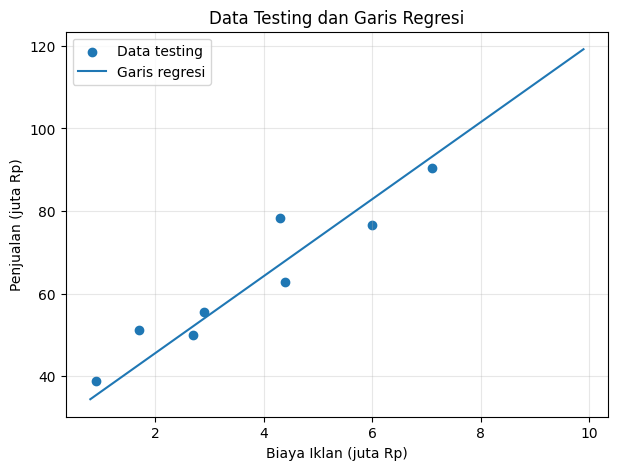

Biaya iklan 4.5 juta Rp -> prediksi penjualan 68.88 juta Rp
Biaya iklan 7.0 juta Rp -> prediksi penjualan 92.17 juta Rp
Biaya iklan 12.0 juta Rp -> prediksi penjualan 138.75 juta Rp


In [8]:
plt.figure(figsize=(7,5))
plt.scatter(X_test[:,0], y_test, label="Data testing")
x_line = np.linspace(X[:,0].min(), X[:,0].max(), 200).reshape(-1,1)
plt.plot(x_line[:,0], lin_model.predict(x_line), label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5],[7.0],[12.0]])
prediksi_baru = lin_model.predict(biaya_baru)
for xval, pred in zip(biaya_baru[:,0], prediksi_baru):
    print(f"Biaya iklan {xval:.1f} juta Rp -> prediksi penjualan {pred:.2f} juta Rp")

**Jawaban A6 (analisis):** Prediksi untuk 4,5 dan 7 juta Rp lebih dapat dipertimbangkan jika nilainya berada dalam rentang data yang diamati. Prediksi 12 juta Rp merupakan ekstrapolasi karena melampaui biaya iklan maksimum pada dataset (9,9 juta Rp). Hasil ekstrapolasi kurang dapat dipercaya karena hubungan linear yang dipelajari dari rentang data yang tersedia belum tentu berlanjut pada biaya iklan yang lebih tinggi.

## Bagian B – Logistic Regression

### B1 – Load & visualisasi data

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris: 60
Jumlah kelas Spam (1) dan Bukan Spam (0):


,Jumlah
Spam,
Bukan Spam (0),35
Spam (1),25


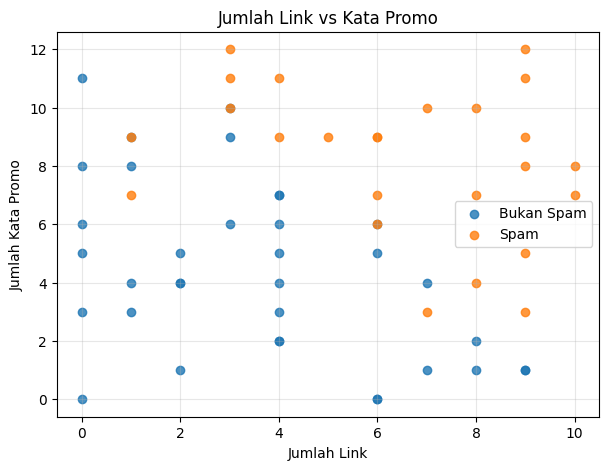

In [9]:
emails = pd.read_csv("Email_Data.csv")
display(emails.head())
print("Jumlah baris:", len(emails))
print("Jumlah kelas Spam (1) dan Bukan Spam (0):")
display(emails["Spam"].value_counts().sort_index().rename(index={0:"Bukan Spam (0)",1:"Spam (1)"}).to_frame("Jumlah"))

X_email = emails[["JumlahLink","KataPromo"]].to_numpy(dtype=float)
y_email = emails["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7,5))
for label, name in [(0,"Bukan Spam"), (1,"Spam")]:
    mask = y_email == label
    plt.scatter(X_email[mask,0], X_email[mask,1], label=name, alpha=0.8)
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### B2 – Split & training Logistic Regression

Intercept: -10.419587167146902
Koefisien [JumlahLink, KataPromo]: [0.8593 0.8887]
logit(p) = -10.4196 + (0.8593 × JumlahLink) + (0.8887 × KataPromo)


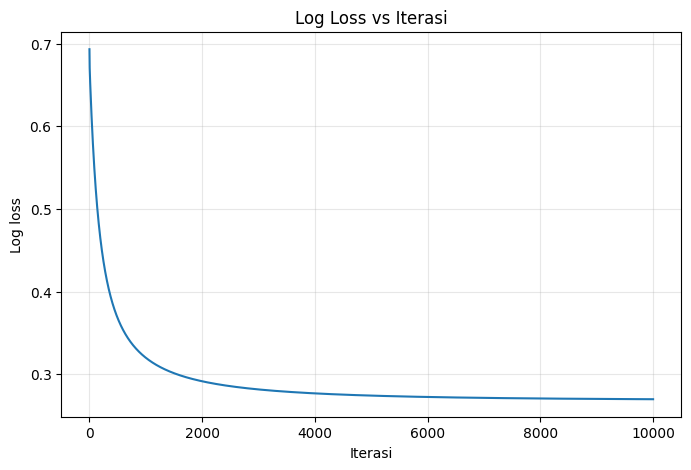

Log loss awal: 0.6931471805579454
Log loss akhir: 0.26980524246032533


In [10]:
Xtr, Xte, ytr, yte = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_b = np.c_[np.ones((len(X),1)), X]
        theta = np.zeros(X_b.shape[1])
        eps = 1e-12
        self.loss_history = []
        for _ in range(self.n_iterations):
            probs = sigmoid(X_b @ theta)
            loss = -np.mean(y*np.log(probs+eps) + (1-y)*np.log(1-probs+eps))
            self.loss_history.append(loss)
            gradients = X_b.T @ (probs-y) / len(y)
            theta -= self.learning_rate * gradients
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_b = np.c_[np.ones((len(X),1)), X]
        p1 = sigmoid(X_b @ np.r_[self.intercept_, self.coef_])
        return np.c_[1-p1, p1]
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:,1] >= threshold).astype(int)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xtr, ytr)
print("Intercept:", log_model.intercept_)
print("Koefisien [JumlahLink, KataPromo]:", log_model.coef_)
print(f"logit(p) = {log_model.intercept_:.4f} + ({log_model.coef_[0]:.4f} × JumlahLink) + ({log_model.coef_[1]:.4f} × KataPromo)")
plt.figure(figsize=(8,5))
plt.plot(log_model.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Log Loss vs Iterasi")
plt.grid(True, alpha=0.3)
plt.show()
print("Log loss awal:", log_model.loss_history[0])
print("Log loss akhir:", log_model.loss_history[-1])

**Analisis B2:** Koefisien model untuk `JumlahLink` adalah sekitar **0,8593**, sedangkan untuk `KataPromo` sekitar **0,8887**. Keduanya positif, sehingga kenaikan nilai fitur tersebut berkaitan dengan kenaikan log-odds prediksi spam ketika fitur lain dianggap tetap. Log loss turun dari sekitar **0,6931** menjadi **0,2698**, yang menunjukkan bahwa proses pelatihan memperbaiki prediksi probabilitas pada data training. Hubungan ini tidak berarti kedua fitur selalu menentukan status spam secara sempurna.

### B3 – Evaluasi model

In [11]:
yte_pred = log_model.predict(Xte, threshold=0.5)
metrics = classification_metrics(yte, yte_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(yte, yte_pred))
display(pd.DataFrame([metrics]).round(4))

Confusion matrix [[TN, FP], [FN, TP]]:
[[9 0]
 [2 4]]


,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.8667,1.0,0.6667,0.8,9,0,2,4


**Analisis B3:** Pada data testing, model memperoleh **accuracy 0,8667**, **precision 1,0000**, **recall 0,6667**, dan **F1-score 0,8000**. Confusion matrix menunjukkan **TN=9, FP=0, FN=2, TP=4**. Artinya, pada sampel testing ini tidak ada email bukan spam yang salah ditandai sebagai spam, tetapi 2 email spam belum berhasil dikenali. Karena jumlah data testing relatif kecil, metrik ini perlu ditafsirkan dengan hati-hati.

### B4 – Decision boundary

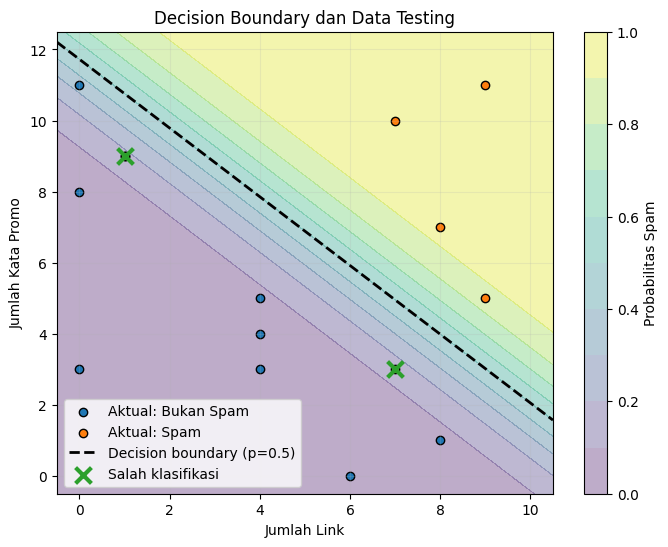

Jumlah salah klasifikasi: 2


,JumlahLink,KataPromo,Aktual,Prediksi,ProbabilitasSpam
0,7.0,3.0,1,0,0.149533
1,1.0,9.0,1,0,0.173398


Decision boundary: intercept + coef_link*JumlahLink + coef_promo*KataPromo = 0


In [12]:
probs_test = log_model.predict_proba(Xte)[:,1]
pred_test = (probs_test >= 0.5).astype(int)
wrong = pred_test != yte

x_min, x_max = X_email[:,0].min()-0.5, X_email[:,0].max()+0.5
y_min, y_max = X_email[:,1].min()-0.5, X_email[:,1].max()+0.5
xx, yy = np.meshgrid(np.linspace(x_min,x_max,250), np.linspace(y_min,y_max,250))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = log_model.predict_proba(grid)[:,1].reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, zz, levels=np.linspace(0,1,11), alpha=0.35)
plt.colorbar(label="Probabilitas Spam")
for label, name in [(0,"Bukan Spam"),(1,"Spam")]:
    mask = yte == label
    plt.scatter(Xte[mask,0], Xte[mask,1], label=f"Aktual: {name}", edgecolors="black")
if abs(log_model.coef_[1]) > 1e-12:
    xb = np.linspace(x_min,x_max,200)
    yb = -(log_model.intercept_ + log_model.coef_[0]*xb)/log_model.coef_[1]
    plt.plot(xb, yb, "k--", linewidth=2, label="Decision boundary (p=0.5)")
if np.any(wrong):
    plt.scatter(Xte[wrong,0], Xte[wrong,1], marker="x", s=130, linewidths=3,
                label="Salah klasifikasi")
plt.xlim(x_min,x_max); plt.ylim(y_min,y_max)
plt.xlabel("Jumlah Link"); plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary dan Data Testing")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

misclassified = pd.DataFrame({
    "JumlahLink":Xte[wrong,0], "KataPromo":Xte[wrong,1],
    "Aktual":yte[wrong], "Prediksi":pred_test[wrong],
    "ProbabilitasSpam":probs_test[wrong]
})
print("Jumlah salah klasifikasi:", int(wrong.sum()))
display(misclassified)
print("Decision boundary: intercept + coef_link*JumlahLink + coef_promo*KataPromo = 0")

**Jawaban B4 (analisis):** Decision boundary berada pada probabilitas 0,5, yaitu garis ketika `intercept + coef_link × JumlahLink + coef_promo × KataPromo = 0`. Tanda silang pada grafik menunjukkan data testing yang prediksinya berbeda dari label aktual. Tabel di atas menampilkan fitur, label aktual, prediksi, dan probabilitas untuk setiap data yang salah diklasifikasikan.

### B5 – Eksperimen threshold

In [13]:
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (probs_test >= threshold).astype(int)
    m = classification_metrics(yte, pred)
    cm = confusion_matrix(yte, pred)
    threshold_rows.append({
        "Threshold":threshold, "TN":cm[0,0], "FP":cm[0,1],
        "FN":cm[1,0], "TP":cm[1,1],
        "Precision":m["Precision"], "Recall":m["Recall"]
    })
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,8,1,2,4,0.8,0.6667
1,0.5,9,0,2,4,1.0,0.6667
2,0.7,9,0,2,4,1.0,0.6667


**Analisis B5:** Pada hasil ini, threshold **0,3** menghasilkan TN=8, FP=1, FN=2, TP=4, precision=0,80, dan recall=0,6667. Threshold **0,5** dan **0,7** menghasilkan TN=9, FP=0, FN=2, TP=4, precision=1,00, dan recall=0,6667. Jadi, pada sampel testing ini perubahan threshold dari 0,5 ke 0,7 tidak mengubah prediksi, sedangkan threshold 0,3 menandai satu email tambahan sebagai spam dan menghasilkan satu false positive. Threshold sebaiknya dipilih sesuai prioritas penggunaan dan diuji pada data yang lebih banyak.

### B6 – Prediksi email baru

In [14]:
new_emails = pd.DataFrame({
    "Email":["E1","E2","E3","E4"],
    "JumlahLink":[1,5,9,2],
    "KataPromo":[2,6,10,11]
})
# Pilihan threshold: 0.3, memprioritaskan recall untuk menangkap spam.
chosen_threshold = 0.3
new_X = new_emails[["JumlahLink","KataPromo"]].to_numpy(dtype=float)
new_proba = log_model.predict_proba(new_X)[:,1]
new_emails["ProbabilitasSpam"] = new_proba
new_emails["PrediksiKelas"] = (new_proba >= chosen_threshold).astype(int)
new_emails["Prediksi"] = new_emails["PrediksiKelas"].map({0:"Bukan Spam",1:"Spam"})
display(new_emails.round(4))
print("Threshold yang digunakan:", chosen_threshold)

,Email,JumlahLink,KataPromo,ProbabilitasSpam,PrediksiKelas,Prediksi
0,E1,1,2,0.0004,0,Bukan Spam
1,E2,5,6,0.3120,1,Spam
2,E3,9,10,0.9980,1,Spam
3,E4,2,11,0.7456,1,Spam


Threshold yang digunakan: 0.3


## Bagian C – Pemahaman Konsep

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena menghasilkan probabilitas suatu contoh masuk ke kelas tertentu, lalu probabilitas tersebut diubah menjadi label menggunakan threshold. Fungsi sigmoid mengubah nilai linear apa pun menjadi angka antara 0 dan 1. Angka tersebut dapat ditafsirkan sebagai probabilitas kelas positif, misalnya email spam. Nama “regression” merujuk pada pemodelan hubungan linear terhadap log-odds, bukan berarti hasil akhirnya harus berupa angka kontinu.

**Jawaban C2:** Normal Equation menghitung parameter regresi secara langsung melalui operasi matriks, sehingga tidak perlu menentukan learning rate atau jumlah iterasi. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih berguna ketika jumlah fitur atau data sangat besar sehingga perhitungan matriks langsung mahal. Namun, hasilnya bergantung pada learning rate, jumlah iterasi, dan skala fitur.

**Jawaban C3:** Data testing dipakai untuk memperkirakan kemampuan model pada data baru yang tidak digunakan saat pelatihan. Evaluasi hanya pada data training bisa memberi gambaran terlalu optimistis karena model sudah menyesuaikan parameter pada data tersebut. Overfitting terjadi ketika model terlalu menyesuaikan diri pada pola atau noise data training dan kinerjanya memburuk pada data baru. Karena itu, hasil training dan testing perlu dibandingkan.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai prediksi dan nilai aktual. Logistic Regression memprediksi probabilitas kelas, sehingga log loss mengukur seberapa baik probabilitas tersebut cocok dengan label sebenarnya. Log loss memberi penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi salah. Fungsi loss ini sesuai dengan sifat output probabilistik pada klasifikasi.

**Jawaban C5:** Hasil dapat berbeda karena pembagian data training/testing berubah sesuai nilai `random_state`. Perbedaan sampel training memengaruhi koefisien dan pola yang dipelajari model. Pada Gradient Descent, learning rate, jumlah iterasi, inisialisasi parameter, dan skala fitur juga dapat memengaruhi hasil. Untuk Logistic Regression, implementasi, regularisasi, dan kriteria berhenti optimasi dapat menimbulkan perbedaan tambahan.

## Bonus – Perbandingan dengan scikit-learn

In [15]:
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score as sk_r2
    from sklearn.metrics import accuracy_score, confusion_matrix as sk_confusion_matrix

    sk_lin = SklearnLinearRegression().fit(X_train, y_train)
    sk_lin_pred = sk_lin.predict(X_test)
    print("Linear Regression - NumPy:")
    print(" intercept:", lin_model.intercept_, "coef:", lin_model.coef_)
    print("Linear Regression - scikit-learn:")
    print(" intercept:", sk_lin.intercept_, "coef:", sk_lin.coef_)
    print("R2 testing NumPy:", r2_score(y_test, y_test_pred))
    print("R2 testing scikit-learn:", sk_r2(y_test, sk_lin_pred))

    # C besar mendekati tanpa regularisasi, tetapi solver dan toleransi tetap berpengaruh.
    sk_log = SklearnLogisticRegression(C=1e6, penalty="l2", solver="lbfgs", max_iter=10000)
    sk_log.fit(Xtr, ytr)
    sk_pred = sk_log.predict(Xte)
    print("\nLogistic Regression - NumPy:")
    print(" intercept:", log_model.intercept_, "coef:", log_model.coef_)
    print("Logistic Regression - scikit-learn (C=1e6, penalty='l2'):")
    print(" intercept:", sk_log.intercept_[0], "coef:", sk_log.coef_[0])
    print("Accuracy NumPy:", classification_metrics(yte, yte_pred)["Accuracy"])
    print("Accuracy scikit-learn:", np.mean(sk_pred == yte))
    print("Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:")
    print(sk_confusion_matrix(yte, sk_pred, labels=[0,1]))
except ImportError:
    print("scikit-learn belum terpasang. Bagian bonus dapat dijalankan di lingkungan yang memiliki scikit-learn.")

Linear Regression - NumPy:
 intercept: 26.96410209662742 coef: [9.3156]
Linear Regression - scikit-learn:
 intercept: 26.964102096627187 coef: [9.3156]
R2 testing NumPy: 0.8610872824226858
R2 testing scikit-learn: 0.8610872824226834

Logistic Regression - NumPy:
 intercept: -10.419587167146902 coef: [0.8593 0.8887]
Logistic Regression - scikit-learn (C=1e6, penalty='l2'):
 intercept: -11.729544304767305 coef: [0.9837 0.9847]
Accuracy NumPy: 0.8666666666666667
Accuracy scikit-learn: 0.8666666666666667
Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:
[[9 0]
 [2 4]]


**Analisis bonus:** Koefisien Linear Regression dari implementasi NumPy dan `scikit-learn` hampir sama, dan keduanya menghasilkan R² testing sekitar **0,8611**. Pada Logistic Regression, accuracy kedua implementasi sama-sama **0,8667** pada pembagian data ini, meskipun koefisiennya berbeda. Salah satu penyebabnya adalah perbedaan metode optimasi dan regularisasi; implementasi `scikit-learn` pada notebook menggunakan regularisasi yang sangat lemah (`C=1e6`), sedangkan model NumPy tidak menambahkan regularisasi eksplisit.

## Checklist sebelum dikumpulkan

- [x] Identitas: Kiki Damayanti, NIM 211011400758, kelas Reguler B.
- [ ] Kedua dataset (`Ads_Data.csv` dan `Email_Data.csv`) tersedia saat menjalankan notebook.
- [ ] Semua sel dijalankan berurutan dan tidak ada error yang belum ditangani.
- [ ] Tabel evaluasi dan grafik tampil dengan benar.
- [ ] Notebook disimpan setelah eksekusi, sehingga output ikut tersimpan.
- [ ] Jika diminta dosen, unggah notebook, kedua CSV, dan README ke repository GitHub.
- [ ] Baca kembali analisis dan pastikan dapat menjelaskan arti metrik, grafik, dan hasil model dengan kata-kata sendiri.